# Polynomial Regression

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from prettytable import PrettyTable

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression

In [2]:
RANDOM_STATE = 42

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

## 1 Introduction

### 1.1 Linear Relationship

#### Example

$$
\large
y\;=\;w \cdot x
$$

In [3]:
# Temporary Random number generator .
rng1 = np.random.default_rng(seed=0)

In [4]:
# Generate Feature, noise and Target.
ftr1 = rng1.uniform(-4, 4, size=100)
noise = rng1.normal(-4, 4, size=100)
w = rng1.integers(10)
trgt = (w * ftr1) + noise  # y = (x^2 + noise)

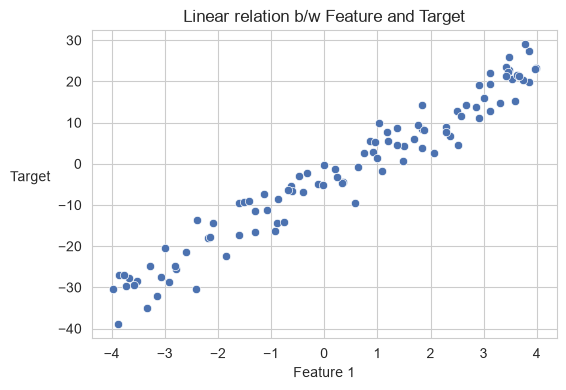

In [5]:
plt.figure(figsize=(6, 4))

sns.scatterplot(x=ftr1, y=trgt)
plt.title("Linear relation b/w Feature and Target")
plt.xlabel("Feature 1")
plt.ylabel("Target", rotation=0, labelpad=20)

plt.show()

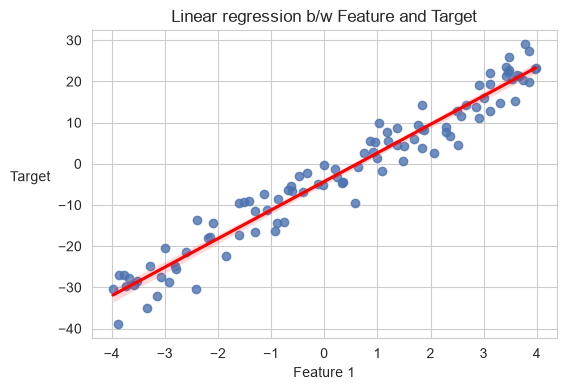

In [6]:
plt.figure(figsize=(6, 4))

sns.regplot(x=ftr1, y=trgt, line_kws={"color": "red"})
plt.title("Linear regression b/w Feature and Target")
plt.xlabel("Feature 1")
plt.ylabel("Target", rotation=0, labelpad=20)

plt.show()

### 1.2 Non Linear Relationship

#### What is Non Linear Relationship?

Relationship between Features and Target are not always Linear (a straight line), it can be complex non-linear (parabolic for example).

#### Example

$$
\large
y\;=\;w \cdot x^2
$$

In [7]:
# Generate Feature, noise and Target.
ftr1 = rng1.uniform(-4, 4, size=100)
noise = rng1.normal(-1, 1, size=100)
trgt = (ftr1**2) + noise  # y = (x^2 + noise)

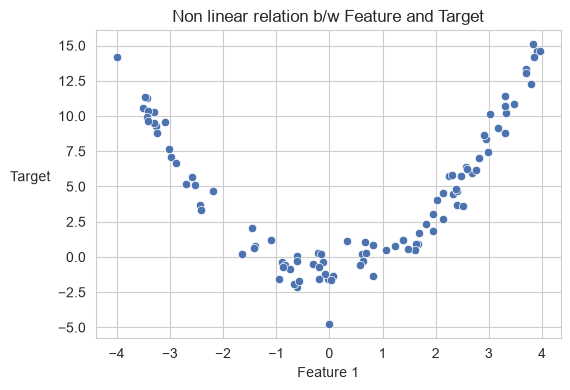

In [8]:
plt.figure(figsize=(6, 4))

sns.scatterplot(x=ftr1, y=trgt)
plt.title("Non linear relation b/w Feature and Target")
plt.xlabel("Feature 1")
plt.ylabel("Target", rotation=0, labelpad=20)

plt.show()

#### Why do we need Polynomial Regression?

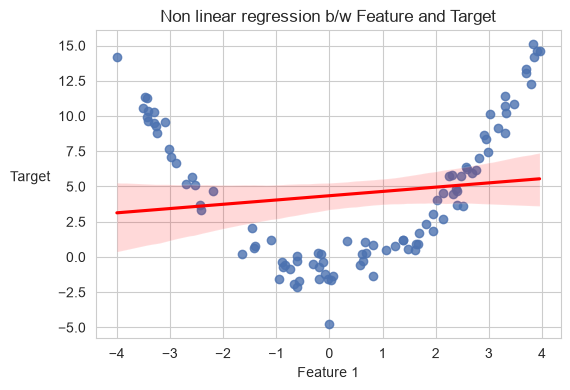

In [9]:
plt.figure(figsize=(6, 4))

sns.regplot(x=ftr1, y=trgt, line_kws={"color": "red"})
plt.title("Non linear regression b/w Feature and Target")
plt.xlabel("Feature 1")
plt.ylabel("Target", rotation=0, labelpad=20)

plt.show()

- A straight line cannot capture above non linear relationship.
- Linear Regression cannot train a model to capture above non linear relation.
- Hence we need **Polynomial Regression to capture non linear relationships**.

### 1.3 Dummy Dataset

#### Features and Target Variables

In [10]:
# 100 rows 3 columns.
n, d = 100, 6

# Generate random weights.
weights = rng.uniform(-5, 5, d)

# Generate empty feature matrix of zeros.
X = np.zeros(shape=(n, d), dtype=float)

# Add features to features matrix.
X[:, 0] = rng.normal(0, 3, size=n)  # Feature 1
X[:, 1] = rng.exponential(2, size=n).clip(-6, 6)  # Feature 2
X[:, 2] = rng.uniform(-6, 6, size=n)  # Feature 3

X[:, 3] = X[:, 0] ** 2  # Feature 4
X[:, 4] = X[:, 1] ** 2  # Feature 5
X[:, 5] = X[:, 2] ** 2  # Feature 6

noise = rng.normal(0, 1, n)

# Generate random Target values.
y = (X @ weights) + noise

# Convert into Pandas DataFrame.
smp_df = pd.DataFrame(X, columns=[f"Feature {i+1}" for i in range(d)])
smp_df["Target"] = y

row_count, col_count = smp_df.shape
smp_df.head()

,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Target
0,0.383521,0.438108,2.331149,0.147089,0.191939,5.434257,32.743546
1,-0.948728,4.289835,0.973399,0.900084,18.402682,0.947506,-69.801749
2,-0.050403,0.280606,-3.602692,0.002541,0.078740,12.979391,49.916932
3,-2.559132,0.375798,3.649494,6.549155,0.141224,13.318809,80.012610
4,2.638194,0.620483,2.584886,6.960067,0.385000,6.681633,60.935289


#### EDA

##### Correlation Matrix

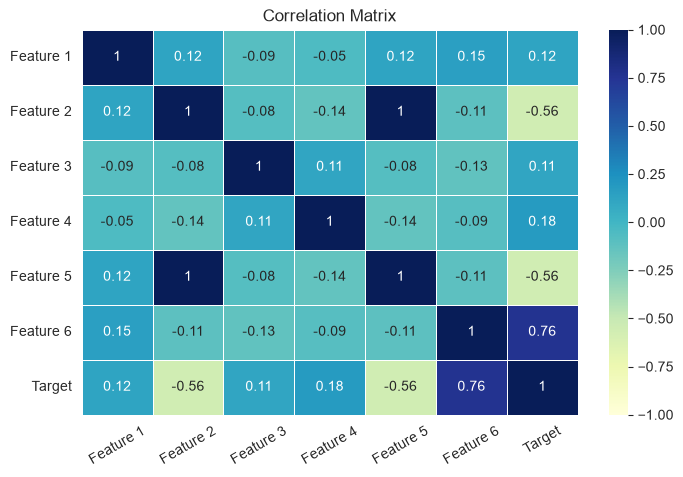

In [11]:
corr = smp_df.corr(numeric_only=True, method="spearman").round(2)

plt.figure(figsize=(8, 5))
sns.heatmap(corr, cmap="YlGnBu", linecolor="white", linewidth=0.5, vmin=-1, vmax=1, annot=True)
plt.title("Correlation Matrix")
plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.show()

##### Distributions

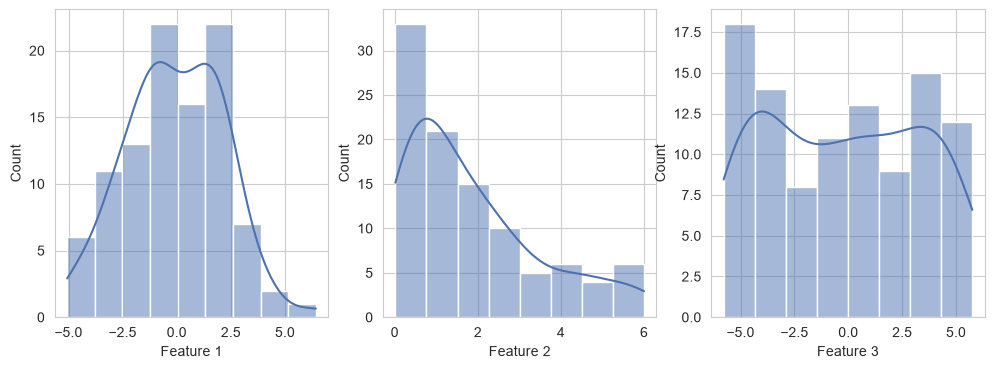

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.histplot(data=smp_df, x="Feature 1", kde=True)

plt.subplot(1, 3, 2)
sns.histplot(data=smp_df, x="Feature 2", kde=True)

plt.subplot(1, 3, 3)
sns.histplot(data=smp_df, x="Feature 3", kde=True)

plt.show()

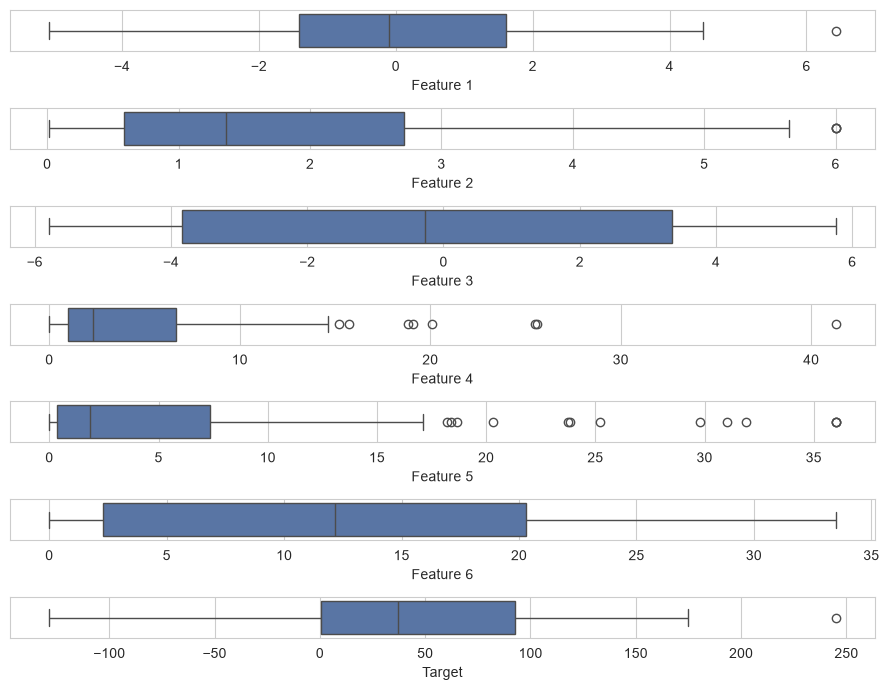

In [13]:
plt.figure(figsize=(9, 7))

for idx, col_name in enumerate(smp_df.columns):
    plt.subplot(col_count, 1, idx + 1)
    sns.boxplot(data=smp_df, x=col_name)

plt.tight_layout()
plt.show()

##### Non Linear Relation

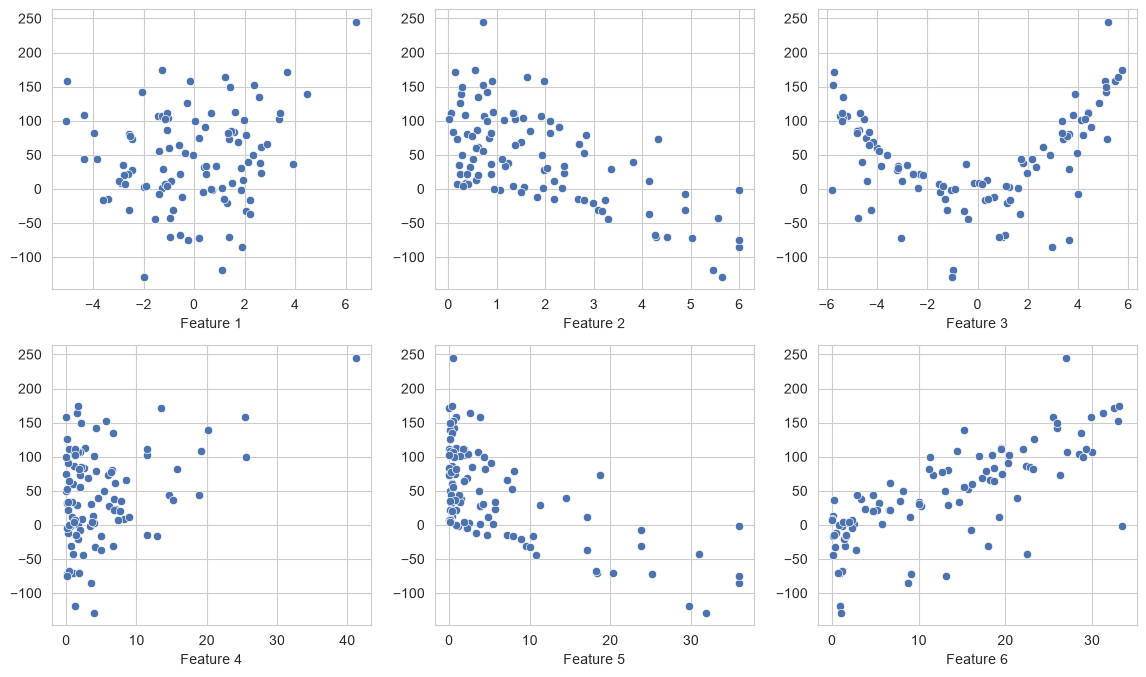

In [14]:
plt.figure(figsize=(14, 8))

for col_idx in range(d):
    plt.subplot(2, 3, col_idx + 1)
    sns.scatterplot(smp_df, x=f"Feature {col_idx + 1}", y="Target")
    plt.ylabel(None)

plt.show()

#### Feature Scaling

In [15]:
def feature_scaling(df, target_col_name: str):
    """
    Function to perform Feature Scaling on input `df` DataFrame.
    """
    sclr = StandardScaler().set_output(transform="pandas")
    scld_df = sclr.fit_transform(df.drop(columns=target_col_name))
    scld_df[target_col_name] = df[target_col_name]

    return scld_df

In [16]:
# smp_df = feature_scaling(smp_df, "Target")
# smp_df.head()

## 2 Polynomial Regression

### 2.1 Introduction

#### Definition

Polynomial regression is a form of regression analysis that models the non-linear relationship between an independent variable $X$ and a dependent variable $y$ by fitting a $n^\text{th}$ degree polynomial.

#### What is Polynomial Regression?

Transforming non-linear problem into a linear problem by introducing polynomial features, using some Feature Transformation techniques, is called as Polynomial Regression.

#### Degree of Polynomial

- Highest degree in Polynomial Regression of is called as Degree of Polynomial.
- Example degree of regression: $\hat{y}\;=\;w_1\,x_1^2\;+\;w_2\,x_2^4\;+\;w_3\,x_3^2\;+\;w_0$ is 4.
- Also known as Order of Features.

### 2.2 Polynomial Features

#### Feature Transformations

- Transformed Features are linearly related to Target.

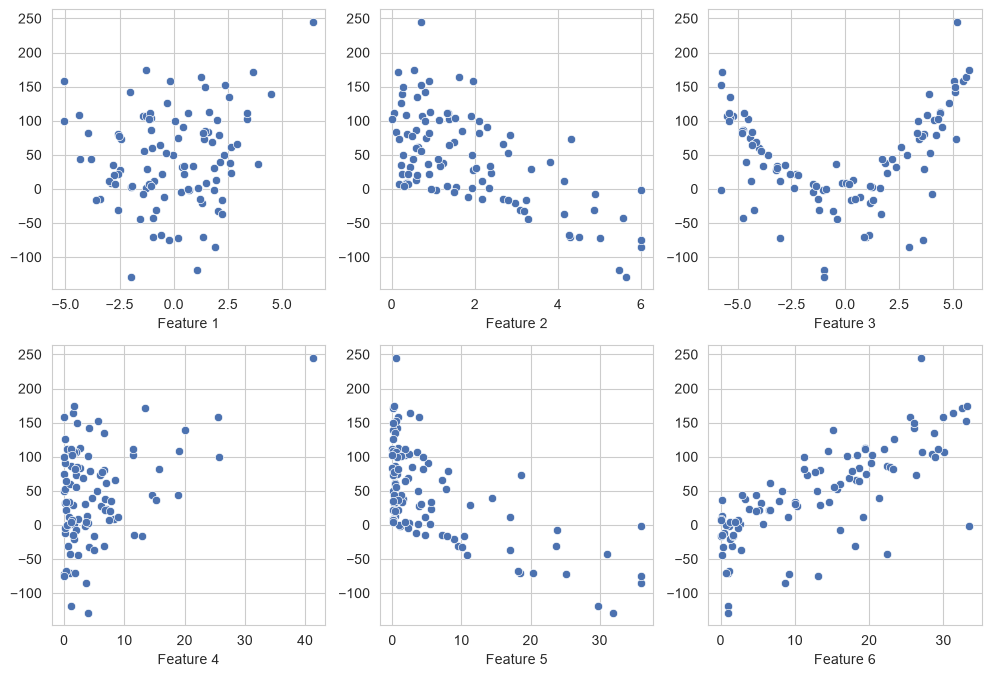

In [17]:
plt.figure(figsize=(12, 8))

for col_idx in range(d):
    plt.subplot(2, 3, col_idx + 1)
    sns.scatterplot(smp_df, x=f"Feature {col_idx + 1}", y="Target")
    plt.ylabel(None)

plt.show()

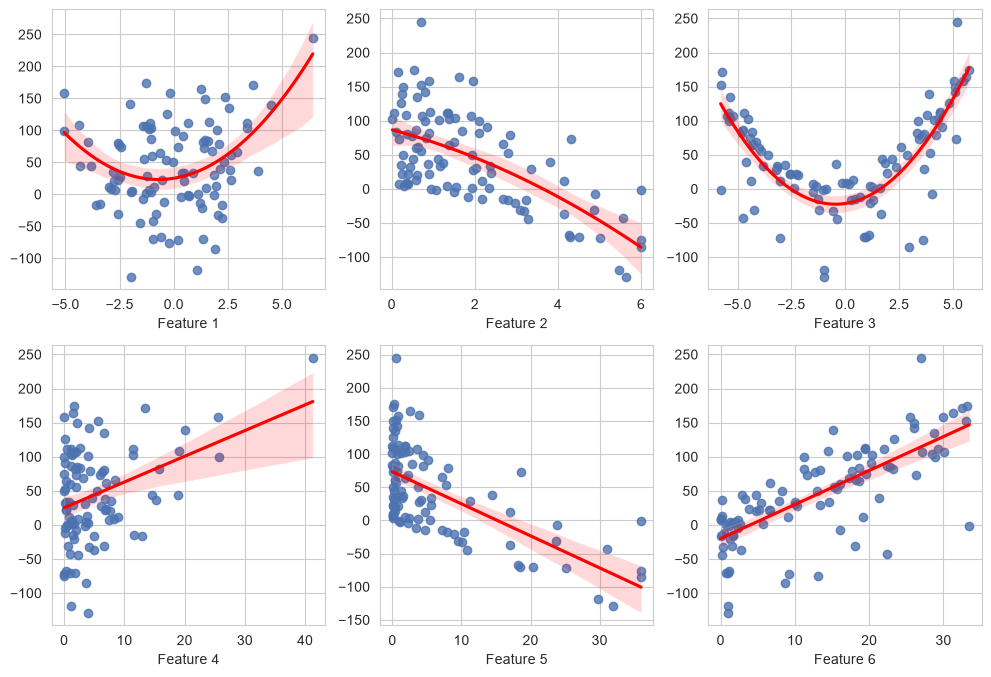

In [18]:
plt.figure(figsize=(12, 8))

for col_idx in range(d):
    order = 2 - (col_idx // 3)
    plt.subplot(2, 3, col_idx + 1)
    sns.regplot(smp_df, x=f"Feature {col_idx + 1}", y="Target", order=order, line_kws={"color": "red"})
    plt.ylabel(None)

plt.show()

#### Multicollinearity Test

In [19]:
# Import Code to calculate VIF.
%run ./ml_utils.ipynb

In [20]:
get_vif_ledger(df=smp_df.drop(columns="Target"))

,Feature,VIF
0,Feature 2,12.200846
1,Feature 5,12.047505
2,Feature 4,1.098501
3,Feature 3,1.083625
4,Feature 6,1.077877
5,Feature 1,1.050616
6,const,1.000000


> **Note**:
>
> Feature Scaling had no impact on VIF values.

#### Disadvantages of Polynomial Regression

1. It is **difficult to interpret** the model coefficients of features of higher order.
2. Polynomial Features may introduce **Multicollinearity** (depending on the distribution).
3. Polynomial Features **increases model complexity** and **does not Generalize** well on unseen data.

### 2.3 Model Complexity

#### Degree vs Complexity

- As degree of polynomial regression increases model tends to memorize training data.
- As degree of polynomial regression increases, model complexity increases.
- As degree of polynomial regression decreases, model generalizes well on unseen (test) data.

#### Example

In [21]:
# New Random number generator.
rng2 = np.random.default_rng(seed=1)

In [22]:
# Generate X values.
x = np.linspace(0, 10, n)

noise = rng2.normal(0, 1, size=n)

amplitude = 5
frequency = 2.5
c = amplitude * np.sin(frequency * x) 

m = 5
y = (m * x) + c
y += noise

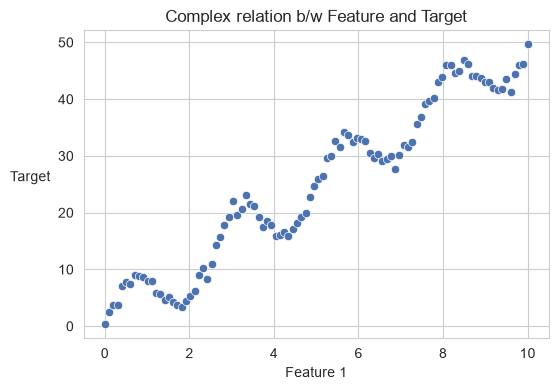

In [23]:
plt.figure(figsize=(6, 4))

sns.scatterplot(x=x, y=y)
plt.title("Complex relation b/w Feature and Target")
plt.xlabel("Feature 1")
plt.ylabel("Target", rotation=0, labelpad=20)

plt.show()

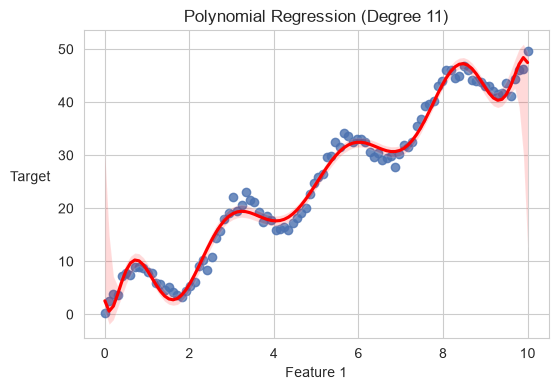

In [24]:
plt.figure(figsize=(6, 4))

sns.regplot(x=x, y=y, order=11, line_kws={"color": "red"})
plt.title("Polynomial Regression (Degree 11)")
plt.xlabel("Feature 1")
plt.ylabel("Target", rotation=0, labelpad=20)

plt.show()